In [2]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import regionmask

from fast_o3_iv import utils, metrics
from fast_o3_iv.config import PROCESSED_DATA_DIR

from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


In [3]:
MODEL_KEYS = [
    "GPR-local",
]

def load_test_results(model_key):
    """Load and concatenate all test-set prediction results for a given model_key.
    """

    TEST_DIR = PROCESSED_DATA_DIR / "model_outputs" / "testing"
    matching_files = sorted(TEST_DIR.glob(f"*.{model_key}.parquet"))

    dfs = []
    for file_path in matching_files:
        parts = file_path.stem.split(".")
        ensemble_member = ".".join(parts[2:4])  # e.g. "wa6_ic3.002"

        df = pd.read_parquet(file_path)
        df["model_key"] = model_key
        df["ensemble_member"] = ensemble_member
        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)

In [4]:
for model_key in MODEL_KEYS:
    df = load_test_results(model_key)
    ds = utils._df_to_ds(df, extra_index_cols=["ensemble_member"])
    

In [5]:
# grab area-weighted mean across populated grid cells for two example regions (WCE + SEA)

# internal variability component in populated grid cells
internal = metrics.return_internal_component(ds)
internal = utils.add_aux_data(internal)
mask = utils.pop_mask(internal)
ds_internal = internal[['val_y_pred', 'val_y_true', 'population_density', 'gw']].where(mask)

# region masks
regions = regionmask.defined_regions.ar6.land 
mask2d = regions.mask(internal) 

# southeast asia : monthly
da_pred_intSEA = utils.area_weighted_mean(ds_internal, 'val_y_pred', mask=mask2d == regions.map_keys("SEA"))
da_true_intSEA = utils.area_weighted_mean(ds_internal, 'val_y_true', mask=mask2d == regions.map_keys("SEA"))

# west-central europe : monthly
da_pred_intWCE = utils.area_weighted_mean(ds_internal, 'val_y_pred', mask=mask2d == regions.map_keys("WCE"))
da_true_intWCE = utils.area_weighted_mean(ds_internal, 'val_y_true', mask=mask2d == regions.map_keys("WCE"))

In [6]:
def calc_peak6m(da):

    roll6 = da.rolling(time=6, min_periods=6).mean()

    # Key detail:
    # A 6-month window ending in Jan–May of year Y includes months from year Y-1;
    # to keep windows entirely within the same calendar year, only consider windows ending in months 6..12.
    roll6_in_year = roll6.where(da["time"].dt.month >= 6)

    # ---- 3) Peak-season (within-year max of 6-month means) ----
    # Group by calendar year of the window endpoint and take the max over time
    peak6m = roll6_in_year.groupby("time.year").max("time")  # dims: (lat, lon, member, year)

    return peak6m

In [46]:
# define monthly and osdma data for WCE and SEA regions
euro_pred_monthly = da_pred_intWCE
euro_true_monthly = da_true_intWCE

euro_pred_osdma = calc_peak6m(euro_pred_monthly)
euro_true_osdma = calc_peak6m(euro_true_monthly)

sea_pred_monthly = da_pred_intSEA
sea_true_monthly = da_true_intSEA

sea_pred_osdma = calc_peak6m(sea_pred_monthly)
sea_true_osdma = calc_peak6m(sea_true_monthly)

In [47]:
import matplotlib as mpl
from matplotlib.lines import Line2D
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import matplotlib as mpl

import numpy as np
from scipy.signal import welch
from scipy.stats import gaussian_kde
from mpl_toolkits.axes_grid1 import make_axes_locatable


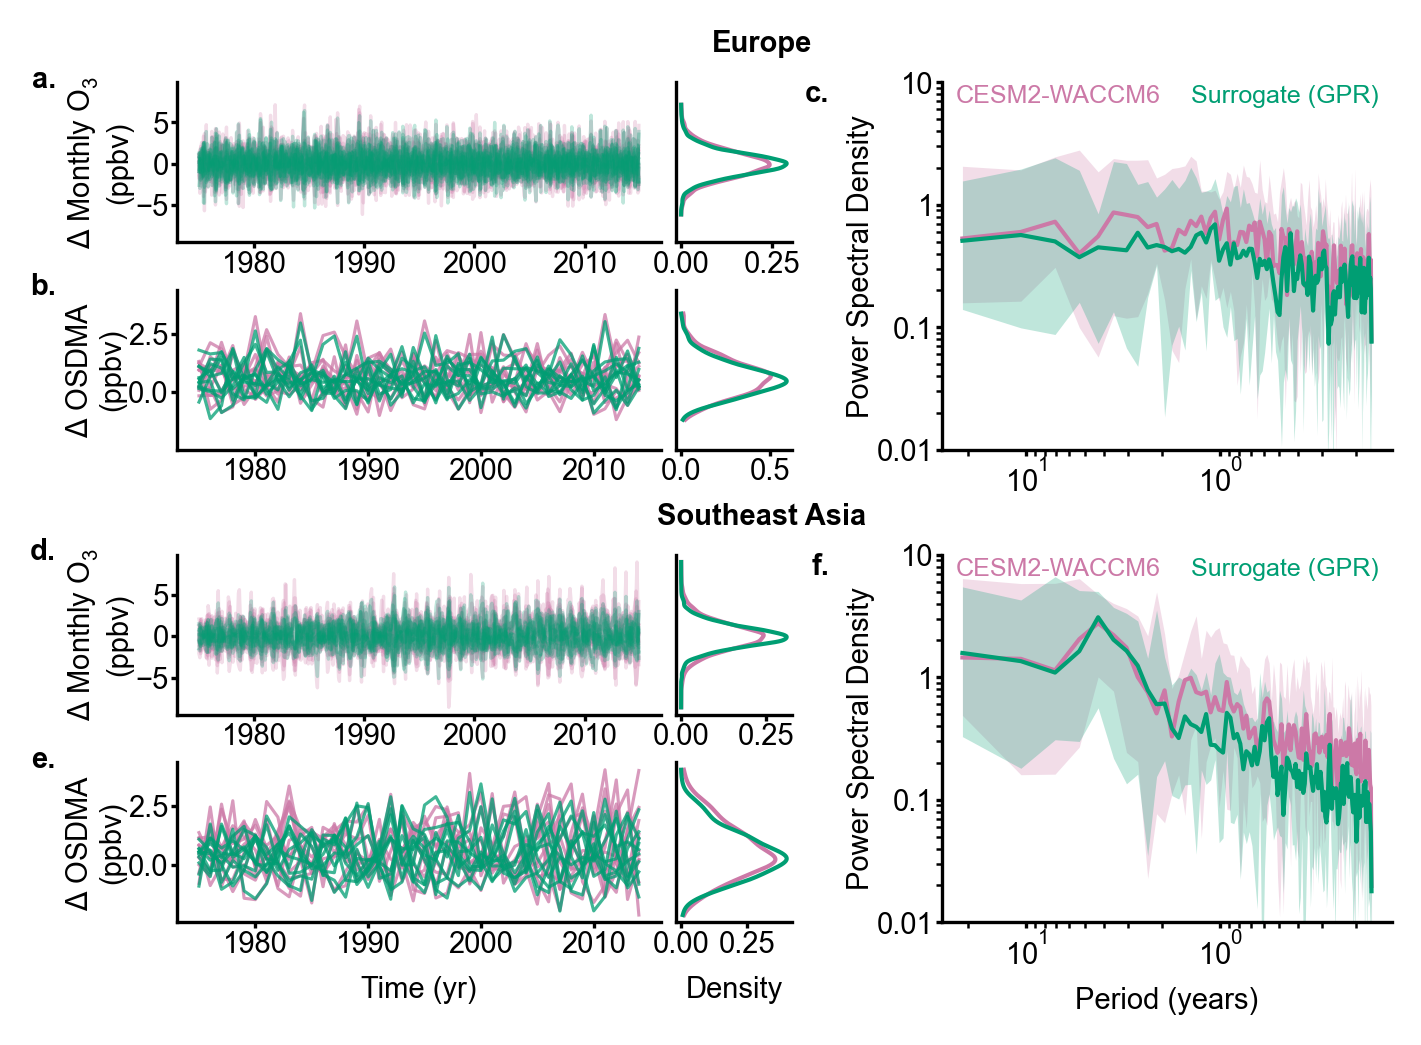

In [ ]:

mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})


color_1 = "#CC79A7"  
color_2   = "#009E73"


def add_text_legend(ax, fontsize=6, loc="upper center", dy=0.02, ncol=2, columnspacing=1.2):
    """custom legend"""
    handles = [
        Line2D([], [], linestyle="None"),
        Line2D([], [], linestyle="None"),
    ]
    labels = ["CESM2-WACCM6", "Surrogate (GPR)"]

    leg = ax.legend(
        handles, labels,
        frameon=False,
        handlelength=0,
        handletextpad=0,
        loc=loc,
        bbox_to_anchor=(0.5, 1.0 + dy),
        borderaxespad=0.0,
        fontsize=fontsize,
        ncol=ncol,
        columnspacing=columnspacing,
    )

    for txt, col in zip(leg.get_texts(), [color_1, color_2]):
        txt.set_color(col)

    return leg


def plot_timeseries_and_kde(
    ax, da_1, da_2,
    xcoord="time", member_dim="ensemble_member",
    color_1=color_1, color_2=color_2,
    alpha=0.25, lw=0.75, mean_lw=1.0,
    kde_n=400, kde_width="24%", kde_pad=0.05
):
    """timeseries + kde subplots for two dataarrays (da_1 and da_2)"""

    # define the timeseries axis
    axt = ax

    # plot timeseries for each individual ensemble members
    for i in range(da_1.sizes[member_dim]):
        axt.plot(
            da_1[xcoord],
            da_1.isel({member_dim: i}).values,
            color=color_1, alpha=alpha, lw=lw
        )
    for i in range(da_2.sizes[member_dim]):
        axt.plot(
            da_2[xcoord],
            da_2.isel({member_dim: i}).values,
            color=color_2, alpha=alpha, lw=lw
        )

    axt.set_xlabel("Time (yr)")

    divider = make_axes_locatable(axt)

    # create the kde axis as a fraction of the timeseries axis
    axk = divider.append_axes("right", size=kde_width, pad=kde_pad, sharey=axt)

    # plot kde for all values in da1 and da2
    x_1 = da_1.values.ravel()
    x_2 = da_2.values.ravel()

    ymin = min(x_1.min(), x_2.min())
    ymax = max(x_1.max(), x_2.max())
    ys = np.linspace(ymin, ymax, kde_n)

    # from scipy.stats
    kde_1 = gaussian_kde(x_1)
    kde_2 = gaussian_kde(x_2)

    axk.plot(kde_1(ys), ys, color=color_1, lw=mean_lw, label="CESM2-WACCM6")
    axk.plot(kde_2(ys), ys, color=color_2, lw=mean_lw, label="Surrogate (GPR)")

    axk.tick_params(axis="y", left=False, labelleft=False)
    axk.grid(False)

    axk.spines["right"].set_visible(False)
    axk.spines["top"].set_visible(False)

    # return timeseries axis obj (axt) and kde axis (axk)
    return axt, axk 


def _psd_stack(da, member_dim, fs, nperseg, detrend):
    """Compute Welch PSDs separately for each ensemble_member in the DataArray `da`
    """
    # define a reference frequency grid
    # is None for now because will be defined from the first processed ensemble member
    f_ref = None

    # initial list of PSDs
    psds = []

    # loop through each ensemble member
    for i in range(da.sizes[member_dim]):
        y = da.isel({member_dim: i}).values

        # return array of frequency values (f) + spectral density (pxx)
        f, psd = welch(y, fs=fs, nperseg=nperseg, detrend=detrend)

        # if f_ref is notdefined (first member) define the first member as the reference freq grid
        if f_ref is None:
            f_ref = f

        # check that the frequency grids are similar so that we can stack PSDs
        elif len(f) != len(f_ref) or not np.allclose(f, f_ref):
            raise ValueError("Frequency grids differ across members; cannot stack PSDs.")
        psds.append(psd)

    # return the reference frequency grid and the stacked PSDs
    return f_ref, np.vstack(psds)


def _center(P, method):
    """how to aggregate the power spectrum across ensemble members
    (either mean or median)"""
    if method == "mean":
        return np.mean(P, axis=0)
    if method == "median":
        return np.median(P, axis=0)
    raise ValueError("center must be 'mean' or 'median'")

def _envelope_bounds(P, method):
    """how to calculate the power spectrum range across ensemble members
    (either min/max or 5-95th percentile)"""
    if method == "minmax":
        return np.min(P, axis=0), np.max(P, axis=0)
    if method == "percentile":
        return np.percentile(P, 5, axis=0), np.percentile(P, 95, axis=0)
    raise ValueError("envelope must be 'minmax' or 'percentile'")


def plot_power_spectrum(
    ax,
    da_1, da_2,
    time_dim="time", member_dim="ensemble_member",
    nperseg=256, detrend="constant",
    color_1=color_1, color_2=color_2,
    loglog=True,
    lw=1.0,
    alpha=0.25,
    center="median",
    envelope="minmax",
):
    fs = 12.0  # sampling frequency: 12 samples/year for monthly data

    def plot_one(da, color):
        """plot the PSD for one data array"""

        # grabbed the stacked PSDs across ensemble members
        f, P = _psd_stack(da, member_dim, fs, nperseg, detrend)

        # drop the zero-frequency term and convert to period (years)
        f, P = f[1:], P[:, 1:]
        period = 1.0 / f
        order = np.argsort(period)
        period, P = period[order], P[:, order]

        # calculate the mid-point (the thick line to be plotted)
        mid = _center(P, center)

        if P.shape[0] > 1:
            # calculate the envelope bounds (the PSD shading)
            lo, hi = _envelope_bounds(P, envelope)

            # fix so we don't break the log-log plot at zeros
            if loglog:
                eps = np.finfo(float).tiny
                lo, hi, mid = np.maximum(lo, eps), np.maximum(hi, eps), np.maximum(mid, eps)

            ax.fill_between(period, lo, hi, color=color, alpha=alpha, linewidth=0)

        plot_fn = ax.loglog if loglog else ax.plot
        plot_fn(period, mid, color=color, lw=lw)

    plot_one(da_1, color_1)
    plot_one(da_2, color_2)

    ax.set_xlabel("Period (years)")
    return ax

# create the plot 
utils.set_matplotlib_font("Arial")

fig = plt.figure(figsize=(5., 3.5), dpi=300)

# europe grids
gs_ts_eu = GridSpec(2, 1, top=0.90, bottom=0.55, left=0.09, right=0.50, hspace=0.30)
gs_psd_eu = GridSpec(1, 1, top=0.90, bottom=0.55, left=0.60, right=0.90)

# southeast asia grids
gs_ts_sea = GridSpec(2, 1, top=0.45, bottom=0.10, left=0.09, right=0.50, hspace=0.30)
gs_psd_sea = GridSpec(1, 1, top=0.45, bottom=0.10, left=0.60, right=0.90)

# europe axes (m = monthly, o = osdma)
ax_m_r1 = fig.add_subplot(gs_ts_eu[0, 0])
ax_o_r1 = fig.add_subplot(gs_ts_eu[1, 0])

# southeast asia axes (m = monthly, o = osdma)
ax_m_r2 = fig.add_subplot(gs_ts_sea[0, 0], sharey=ax_m_r1)
ax_o_r2 = fig.add_subplot(gs_ts_sea[1, 0], sharey=ax_o_r1)

# psd axes
ax_psd_r1 = fig.add_subplot(gs_psd_eu[0, 0]) # europe
ax_psd_r2 = fig.add_subplot(gs_psd_sea[0, 0], sharex=ax_psd_r1, sharey=ax_psd_r1) # southeast asia

# plot the timeseries and kde plots
_, axk1 = plot_timeseries_and_kde(ax_m_r1, euro_true_monthly, euro_pred_monthly,
                                 xcoord="time", alpha=0.25, lw=0.8)
axk1.set_xlabel("") 

_, axk2 = plot_timeseries_and_kde(ax_m_r2, sea_true_monthly, sea_pred_monthly,
                                 xcoord="time", alpha=0.25, lw=0.8)
_, axk3 = plot_timeseries_and_kde(ax_o_r1, euro_true_osdma, euro_pred_osdma,
                                 xcoord="year", alpha=0.75, lw=0.75)
_, axk4 = plot_timeseries_and_kde(ax_o_r2, sea_true_osdma, sea_pred_osdma,
                                 xcoord="year", alpha=0.75, lw=0.75)

# plot the power spectrums
plot_power_spectrum(ax_psd_r1, euro_true_monthly, euro_pred_monthly)
plot_power_spectrum(ax_psd_r2, sea_true_monthly, sea_pred_monthly)
ax_psd_r1.invert_xaxis()

# legend
add_text_legend(ax_psd_r1)
add_text_legend(ax_psd_r2)

# section labels: europe + southeast asia
fig.text(0.48, 0.95, "Europe", ha="center", va="top", fontsize=7, fontweight="bold")
fig.text(0.48, 0.50, "Southeast Asia", ha="center", va="top", fontsize=7, fontweight="bold")

all_axes = [ax_m_r1, ax_o_r1, ax_m_r2, ax_o_r2, ax_psd_r1, ax_psd_r2]
kde_axes = [axk1, axk2, axk3, axk4]

# set y-labels
for ax in (ax_m_r1, ax_m_r2):
    ax.set_ylabel("$\Delta$ Monthly O$_3$\n(ppbv)", labelpad=0.5)
for ax in (ax_o_r1, ax_o_r2):
    ax.set_ylabel("$\Delta$ OSDMA\n(ppbv)", labelpad=0.5)
ax_psd_r1.set_ylabel("Power Spectral Density", labelpad=0.5)
ax_psd_r2.set_ylabel("Power Spectral Density", labelpad=0.5)

# set xticks for the timeseries
xticks_yr = [1980, 1990, 2000, 2010]
ax_o_r1.set_xticks(xticks_yr)
ax_o_r2.set_xticks(xticks_yr)

xticks_mo = pd.to_datetime(['1980', '1990', '2000', '2010'])
ax_m_r1.set_xticks(xticks_mo)
ax_m_r2.set_xticks(xticks_mo)

for ax in (ax_m_r1, ax_m_r2):
    ax.set_xticklabels([str(y) for y in xticks_yr])

def _decimal_log_formatter(y, _pos):
    if y >= 1:
        return f"{y:g}"
    return f"{y:.3f}".rstrip("0").rstrip(".")

# set y ticks for the psd plots
yticks = [1e-2, 1e-1, 1, 1e1]
for ax in (ax_psd_r1, ax_psd_r2):
    ax.set_ylim([1e-2, 1e1])
    ax.set_yticks(yticks)
    ax.yaxis.set_major_formatter(FuncFormatter(_decimal_log_formatter))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda *_: ""))

# remove right/top spins
for ax in all_axes + kde_axes:
    ax.tick_params(axis="both", which="both", pad=0.5, length=1.5)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

# middle rows: remove x-labels and x-tick labels
for ax in (ax_m_r1, ax_m_r2, ax_psd_r1, axk1, axk3, axk2, ax_o_r1):
    ax.set_xlabel("")
    #ax.tick_params(axis="x", labelbottom=False, pad=0.1)

# add label for the bottom kde plot
axk4.set_xlabel("Density")

# add panel labels
panel_labels = ["a.", "b.", "c.", "d.", "e.", "f."]
panel_axes = [ax_m_r1, ax_o_r1, ax_psd_r1, ax_m_r2, ax_o_r2, ax_psd_r2]
for label, ax in zip(panel_labels, panel_axes):
    ax.text(
        -0.25, 0.93, label,
        transform=ax.transAxes,
        fontsize=7, fontweight="bold",
        ha="right", va="bottom",
    )
    
plt.show()